In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
import os

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]



path = '../../DESRES_NATIVE_DATA/BPTI/'

Using posterior index 48, phi = 0.4972

State definitions and free energies:
S1: RMSD range = 0.120-0.160 nm, RMSD(min) = 0.145 nm, F_prior = 0.000 kcal/mol, F_post = 0.020 kcal/mol, DeltaF = +0.020 kcal/mol, n_frames = 2279701, p_prior = 0.5527, p_post = 0.6285
S2: RMSD range = 0.180-0.220 nm, RMSD(min) = 0.190 nm, F_prior = 0.794 kcal/mol, F_post = 1.457 kcal/mol, DeltaF = +0.663 kcal/mol, n_frames = 609579, p_prior = 0.1478, p_post = 0.0492
S3: RMSD range = 0.260-0.300 nm, RMSD(min) = 0.269 nm, F_prior = 2.230 kcal/mol, F_post = 4.670 kcal/mol, DeltaF = +2.440 kcal/mol, n_frames = 45439, p_prior = 0.0110, p_post = 0.0001
S4: RMSD range = 0.320-0.370 nm, RMSD(min) = 0.325 nm, F_prior = 5.293 kcal/mol, F_post = 7.508 kcal/mol, DeltaF = +2.216 kcal/mol, n_frames = 350, p_prior = 0.0001, p_post = 0.0000

Relative free energies vs S1:
S1: DeltaG_prior = 0.000 kcal/mol, DeltaG_post = 0.000 kcal/mol
S2: DeltaG_prior = 0.794 kcal/mol, DeltaG_post = 1.438 kcal/mol
S3: DeltaG_prior = 2.230 kc

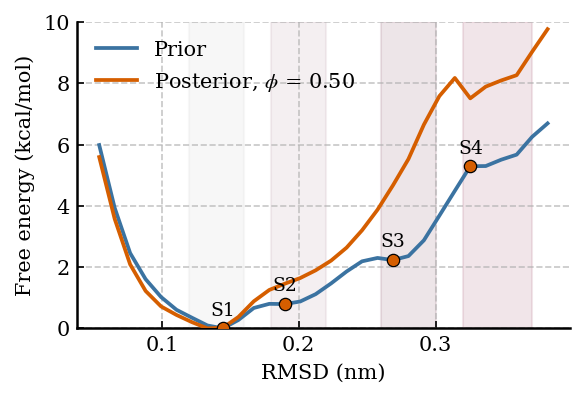

In [31]:
# free energy landscape as a function of RMSD
# define RMSD state regions manually, plot shaded basins,
# and extract frame indices for later analysis

trajs = sorted(find_xtc_filenames(path))
nbins = 30

k = 0.008314
T = 298.0
kT = k * T
KJ_TO_KCAL = 0.239005736

# ------------------------------------------------------------
# Load RMSD
# ------------------------------------------------------------

rmsd = []

for traj in trajs:
    tmp = np.loadtxt(path + f'rmsd_data/rmsd_{traj}.xvg', skiprows=18)[:,1]
    rmsd.append(tmp)

rmsd = np.concatenate(rmsd)

# ------------------------------------------------------------
# Posterior closest to phi = 0.5
# ------------------------------------------------------------

wopt_array = np.load(path + '/rewM14DH_scaled/log_lambda_wopt_array.npy')
rewdata = np.loadtxt(path + '/rewM14DH_scaled/log_lambda_reweighting_chi2_phi_theta.txt')
phi = rewdata[1,:]

post_idx = np.argmin(np.abs(phi - 0.5))
wopt = np.asarray(wopt_array[post_idx], dtype=float)
wopt = wopt / np.sum(wopt)

print(f"Using posterior index {post_idx}, phi = {phi[post_idx]:.4f}")

assert len(rmsd) == len(wopt)

# ------------------------------------------------------------
# Common bins
# ------------------------------------------------------------

bin_edges = np.linspace(rmsd.min(), rmsd.max(), nbins + 1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# prior
counts_prior, _ = np.histogram(rmsd, bins=bin_edges)
p_prior = counts_prior / np.sum(counts_prior)

fel_prior = np.full_like(p_prior, np.nan, dtype=float)
mask_prior = p_prior > 0
fel_prior[mask_prior] = -np.log(p_prior[mask_prior]) * kT * KJ_TO_KCAL
fel_prior = fel_prior - np.nanmin(fel_prior)

# posterior
counts_post, _ = np.histogram(rmsd, bins=bin_edges, weights=wopt)
p_post = counts_post / np.sum(counts_post)

fel_post = np.full_like(p_post, np.nan, dtype=float)
mask_post = p_post > 0
fel_post[mask_post] = -np.log(p_post[mask_post]) * kT * KJ_TO_KCAL
fel_post = fel_post - np.nanmin(fel_post)

# ------------------------------------------------------------
# Define state regions manually
# adjust these if needed
# ------------------------------------------------------------

state_regions = {
    "S1": (0.12, 0.16),   # native minimum
    "S2": (0.18, 0.22),
    "S3": (0.26, 0.30),
    "S4": (0.32, 0.37),
}

state_colors = {
    "S1": "#D9D9D9",
    "S2": "#C9B2BB",
    "S3": "#A97F90",
    "S4": "#BB8194",
}

# ------------------------------------------------------------
# Find local minima within each prior-defined region
# and extract frame indices
# ------------------------------------------------------------

state_info = {}

for state, (lo, hi) in state_regions.items():

    # bins inside this region
    bin_mask = (bin_centers >= lo) & (bin_centers <= hi)

    if np.sum(bin_mask) == 0:
        raise ValueError(f"No histogram bins found in region {state}: {lo}-{hi}")

    region_bins = np.where(bin_mask)[0]
    region_fel_prior = fel_prior[region_bins]

    if not np.any(np.isfinite(region_fel_prior)):
        raise ValueError(f"No finite prior FEL values in region {state}: {lo}-{hi}")

    local_idx = np.nanargmin(region_fel_prior)
    min_bin_idx = region_bins[local_idx]

    # frame indices from raw RMSD values
    frame_mask = (rmsd >= lo) & (rmsd < hi)
    frame_indices = np.where(frame_mask)[0]

    prior_pop = np.mean(frame_mask)
    post_pop = np.sum(wopt[frame_mask])

    state_info[state] = {
        "rmsd_range": (lo, hi),
        "min_bin_idx": min_bin_idx,
        "rmsd_min": bin_centers[min_bin_idx],
        "F_prior": fel_prior[min_bin_idx],
        "F_post": fel_post[min_bin_idx],
        "deltaF": fel_post[min_bin_idx] - fel_prior[min_bin_idx],
        "frame_indices": frame_indices,
        "n_frames": len(frame_indices),
        "prior_pop": prior_pop,
        "post_pop": post_pop,
    }

    np.savetxt(f"{state}_frame_indices.txt", frame_indices, fmt="%d")

# print summary
print("\nState definitions and free energies:")
for state in state_regions:
    info = state_info[state]
    lo, hi = info["rmsd_range"]
    print(
        f"{state}: RMSD range = {lo:.3f}-{hi:.3f} nm, "
        f"RMSD(min) = {info['rmsd_min']:.3f} nm, "
        f"F_prior = {info['F_prior']:.3f} kcal/mol, "
        f"F_post = {info['F_post']:.3f} kcal/mol, "
        f"DeltaF = {info['deltaF']:+.3f} kcal/mol, "
        f"n_frames = {info['n_frames']}, "
        f"p_prior = {info['prior_pop']:.4f}, "
        f"p_post = {info['post_pop']:.4f}"
    )

# relative free energies vs S1
Fprior_S1 = state_info["S1"]["F_prior"]
Fpost_S1 = state_info["S1"]["F_post"]

print("\nRelative free energies vs S1:")
for state in state_regions:
    info = state_info[state]
    dG_prior = info["F_prior"] - Fprior_S1
    dG_post = info["F_post"] - Fpost_S1
    print(f"{state}: DeltaG_prior = {dG_prior:.3f} kcal/mol, DeltaG_post = {dG_post:.3f} kcal/mol")

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

COLOR_PRIOR = "#3B73A1"
COLOR_POST = "#D55E00"

fig, ax = plt.subplots(figsize=(4, 2.75))

# shaded state regions
for state, (lo, hi) in state_regions.items():
    ax.axvspan(lo, hi, color=state_colors[state], alpha=0.20, zorder=0)

# FEL lines
ax.plot(bin_centers, fel_prior, color=COLOR_PRIOR, linewidth=1.8, label="Prior", zorder=2)
ax.plot(bin_centers, fel_post, color=COLOR_POST, linewidth=1.8, label=rf"Posterior, $\phi$ = {phi[post_idx]:.2f}", zorder=3)

# mark minima within each region
for state in state_regions:
    info = state_info[state]
    x = info["rmsd_min"]
    y = info["F_prior"]

    ax.scatter(x, y, s=35, color=COLOR_POST if state != "S1" else COLOR_POST, edgecolor="black", linewidth=0.6, zorder=5)
    ax.text(x, y + 0.30, state, ha="center", va="bottom", fontsize=9)

ax.set_xlabel("RMSD (nm)")
ax.set_ylabel("Free energy (kcal/mol)")
ax.set_ylim(0, 10)
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", which="both", top=False)
ax.tick_params(axis="y", which="both", right=False)

plt.tight_layout()
plt.savefig("RMSD_FEL_states_phi05.pdf")
plt.show()

In [32]:
# secondary structure calculation

import mdtraj as md

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity

# Function to calculate per-residue helicity per frame
def dssp_to_strand(dssp_lines):
    """
    same thing for beta strand
    """
    strand_codes = {'E', 'B'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    strandicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        strandicity[i, :] = [1 if c in strand_codes else 0 for c in line]
    
    return strandicity

'''
# comparison with secondary structure / helicity
path = '../../DESRES_NATIVE_DATA/BPTI/'

traj_names = np.sort(find_xtc_filenames(path))

dssp_all = []

for traj in traj_names:
    print(traj)
    u = md.load(
        path + f'./{traj}',
        top=path + f'./protein.pdb'
    )


    heavyatoms = u.topology.select('not element H')
    u = u.atom_slice(heavyatoms)

    tmpdssp = md.compute_dssp(u)
    dssp_all.append(tmpdssp)

dssp = np.concatenate(dssp_all, axis=0)
np.save(path+'dssp_all_trajs.npy', dssp)
'''


"\n# comparison with secondary structure / helicity\npath = '../../DESRES_NATIVE_DATA/BPTI/'\n\ntraj_names = np.sort(find_xtc_filenames(path))\n\ndssp_all = []\n\nfor traj in traj_names:\n    print(traj)\n    u = md.load(\n        path + f'./{traj}',\n        top=path + f'./protein.pdb'\n    )\n\n\n    heavyatoms = u.topology.select('not element H')\n    u = u.atom_slice(heavyatoms)\n\n    tmpdssp = md.compute_dssp(u)\n    dssp_all.append(tmpdssp)\n\ndssp = np.concatenate(dssp_all, axis=0)\nnp.save(path+'dssp_all_trajs.npy', dssp)\n"

In [ ]:
# secondary-structure propensity of excited state
# State definitions and free energies:
'''
S1: RMSD range = 0.120-0.160 nm
S2: RMSD range = 0.180-0.220 nm
S3: RMSD range = 0.260-0.300 nm
S4: RMSD range = 0.320-0.370 nm
'''

# calculate per-frame secondary-structure assignments
path = '../../DESRES_NATIVE_DATA/BPTI/'
dssp = np.load(path+'dssp_all_trajs.npy')
helicity = dssp_to_helicity(dssp)
strand = dssp_to_strand(dssp)

mask_N = (rmsd > 0.12) & (rmsd < 0.16)
mask_E = (rmsd > 0.18) & (rmsd < 0.22)

# residue axis
residues = np.arange(1, helicity.shape[1] + 1)

# posterior weights
wopt = np.load(path+'/rewM14DH_scaled/log_lambda_wopt_array.npy')[post_idx]


print(f'E frames: {np.sum(mask_E)}')
print(f'N frames: {np.sum(mask_N)}')
print(f'E posterior population: {np.sum(wopt[mask_E]):.4f}')
print(f'N posterior population: {np.sum(wopt[mask_N]):.4f}')

# weighted propensities
alpha_E = np.average(helicity[mask_E], axis=0, weights=wopt[mask_E])
beta_E = np.average(strand[mask_E], axis=0, weights=wopt[mask_E])
alpha_N = np.average(helicity[mask_N], axis=0, weights=wopt[mask_N])
beta_N = np.average(strand[mask_N], axis=0, weights=wopt[mask_N])

# plot
fig, ax = plt.subplots(figsize=(3.0, 5.5))

# intermediate state as bars
ax.barh(residues, -beta_E, height=0.8, color="#D9D9D9", edgecolor="none", label="I")
ax.barh(residues, alpha_E, height=0.8, color="#D9D9D9", edgecolor="none")

# native state as dashed lines
ax.plot(-beta_N, residues, ls="--", lw=1.8, color="#BB8194", label="N")
ax.plot(alpha_N, residues, ls="--", lw=1.8, color="#BB8194")

# thick central axis at x = 0
ax.axvline(0, color="k", lw=2.2)

# limits
ax.set_xlim(-1.03, 1.03)
ax.set_ylim(0.5, len(residues) + 0.5)
ax.invert_yaxis()

# axis labels
ax.set_ylabel("Residue")
ax.set_xlabel("Propensity", labelpad=24)

# x ticks
ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax.set_xticklabels(["1.0", "0.5", "0", "0.5", "1.0"])

# x-axis secondary-structure labels
ax.text(0.25, -0.10, r"$\beta$-strand", transform=ax.transAxes, ha="center", va="top")
ax.text(0.75, -0.10, r"$\alpha$-helix", transform=ax.transAxes, ha="center", va="top")

# y ticks
yticks = np.arange(0, len(residues) + 1, 10)
ax.set_yticks(yticks)
ax.set_yticklabels(yticks)

# styling
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.tick_params(axis="y", left=False, right=False, length=0)
ax.tick_params(axis="x", direction="out", top=False)
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig('N_excited_states_SS_2.pdf', bbox_inches="tight")
plt.show()

E frames: 45439
N frames: 2279697
E posterior population: 0.0001
N posterior population: 0.6285


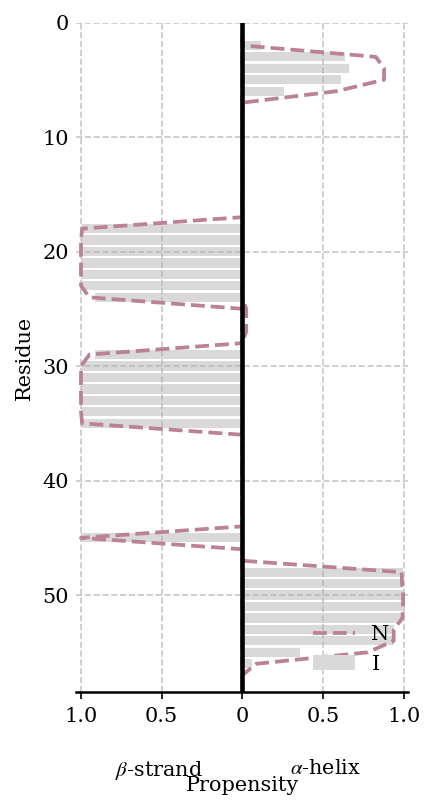

In [ ]:
# secondary-structure propensity of excited state
# State definitions and free energies:
'''
S1: RMSD range = 0.120-0.160 nm
S2: RMSD range = 0.180-0.220 nm
S3: RMSD range = 0.260-0.300 nm
S4: RMSD range = 0.320-0.370 nm
'''

# calculate per-frame secondary-structure assignments
path = '../../DESRES_NATIVE_DATA/BPTI/'
dssp = np.load(path+'dssp_all_trajs.npy')
helicity = dssp_to_helicity(dssp)
strand = dssp_to_strand(dssp)

mask_N = (rmsd > 0.12) & (rmsd < 0.16)
mask_E = (rmsd > 0.26) & (rmsd < 0.30)

# residue axis
residues = np.arange(1, helicity.shape[1] + 1)

# posterior weights
wopt = np.load(path+'/rewM14DH_scaled/log_lambda_wopt_array.npy')[post_idx]


print(f'E frames: {np.sum(mask_E)}')
print(f'N frames: {np.sum(mask_N)}')
print(f'E posterior population: {np.sum(wopt[mask_E]):.4f}')
print(f'N posterior population: {np.sum(wopt[mask_N]):.4f}')

# weighted propensities
alpha_E = np.average(helicity[mask_E], axis=0, weights=wopt[mask_E])
beta_E = np.average(strand[mask_E], axis=0, weights=wopt[mask_E])
alpha_N = np.average(helicity[mask_N], axis=0, weights=wopt[mask_N])
beta_N = np.average(strand[mask_N], axis=0, weights=wopt[mask_N])

# plot
fig, ax = plt.subplots(figsize=(3.0, 5.5))

# intermediate state as bars
ax.barh(residues, -beta_E, height=0.8, color="#D9D9D9", edgecolor="none", label="I")
ax.barh(residues, alpha_E, height=0.8, color="#D9D9D9", edgecolor="none")

# native state as dashed lines
ax.plot(-beta_N, residues, ls="--", lw=1.8, color="#BB8194", label="N")
ax.plot(alpha_N, residues, ls="--", lw=1.8, color="#BB8194")

# thick central axis at x = 0
ax.axvline(0, color="k", lw=2.2)

# limits
ax.set_xlim(-1.03, 1.03)
ax.set_ylim(0.5, len(residues) + 0.5)
ax.invert_yaxis()

# axis labels
ax.set_ylabel("Residue")
ax.set_xlabel("Propensity", labelpad=24)

# x ticks
ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax.set_xticklabels(["1.0", "0.5", "0", "0.5", "1.0"])

# x-axis secondary-structure labels
ax.text(0.25, -0.10, r"$\beta$-strand", transform=ax.transAxes, ha="center", va="top")
ax.text(0.75, -0.10, r"$\alpha$-helix", transform=ax.transAxes, ha="center", va="top")

# y ticks
yticks = np.arange(0, len(residues) + 1, 10)
ax.set_yticks(yticks)
ax.set_yticklabels(yticks)

# styling
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.tick_params(axis="y", left=False, right=False, length=0)
ax.tick_params(axis="x", direction="out", top=False)
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig('N_excited_states_SS_3.pdf', bbox_inches="tight")
plt.show()

E frames: 350
N frames: 2279697
E posterior population: 0.0000
N posterior population: 0.6285


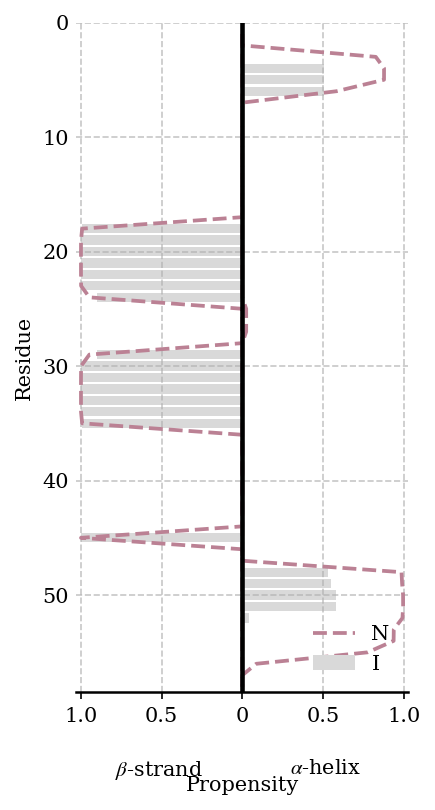

In [ ]:
# secondary-structure propensity of excited state
# State definitions and free energies:
'''
S1: RMSD range = 0.120-0.160 nm
S2: RMSD range = 0.180-0.220 nm
S3: RMSD range = 0.260-0.300 nm
S4: RMSD range = 0.320-0.370 nm
'''

# calculate per-frame secondary-structure assignments
path = '../../DESRES_NATIVE_DATA/BPTI/'
dssp = np.load(path+'dssp_all_trajs.npy')
helicity = dssp_to_helicity(dssp)
strand = dssp_to_strand(dssp)

mask_N = (rmsd > 0.12) & (rmsd < 0.16)
mask_E = (rmsd > 0.32) & (rmsd < 0.37)

# residue axis
residues = np.arange(1, helicity.shape[1] + 1)

# posterior weights
wopt = np.load(path+'/rewM14DH_scaled/log_lambda_wopt_array.npy')[post_idx]


print(f'E frames: {np.sum(mask_E)}')
print(f'N frames: {np.sum(mask_N)}')
print(f'E posterior population: {np.sum(wopt[mask_E]):.4f}')
print(f'N posterior population: {np.sum(wopt[mask_N]):.4f}')

# weighted propensities
alpha_E = np.average(helicity[mask_E], axis=0, weights=wopt[mask_E])
beta_E = np.average(strand[mask_E], axis=0, weights=wopt[mask_E])
alpha_N = np.average(helicity[mask_N], axis=0, weights=wopt[mask_N])
beta_N = np.average(strand[mask_N], axis=0, weights=wopt[mask_N])

# plot
fig, ax = plt.subplots(figsize=(3.0, 5.5))

# intermediate state as bars
ax.barh(residues, -beta_E, height=0.8, color="#D9D9D9", edgecolor="none", label="I")
ax.barh(residues, alpha_E, height=0.8, color="#D9D9D9", edgecolor="none")

# native state as dashed lines
ax.plot(-beta_N, residues, ls="--", lw=1.8, color="#BB8194", label="N")
ax.plot(alpha_N, residues, ls="--", lw=1.8, color="#BB8194")

# thick central axis at x = 0
ax.axvline(0, color="k", lw=2.2)

# limits
ax.set_xlim(-1.03, 1.03)
ax.set_ylim(0.5, len(residues) + 0.5)
ax.invert_yaxis()

# axis labels
ax.set_ylabel("Residue")
ax.set_xlabel("Propensity", labelpad=24)

# x ticks
ax.set_xticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax.set_xticklabels(["1.0", "0.5", "0", "0.5", "1.0"])

# x-axis secondary-structure labels
ax.text(0.25, -0.10, r"$\beta$-strand", transform=ax.transAxes, ha="center", va="top")
ax.text(0.75, -0.10, r"$\alpha$-helix", transform=ax.transAxes, ha="center", va="top")

# y ticks
yticks = np.arange(0, len(residues) + 1, 10)
ax.set_yticks(yticks)
ax.set_yticklabels(yticks)

# styling
ax.spines["left"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(False)
ax.tick_params(axis="y", left=False, right=False, length=0)
ax.tick_params(axis="x", direction="out", top=False)
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.savefig('N_excited_states_SS_4.pdf', bbox_inches="tight")
plt.show()

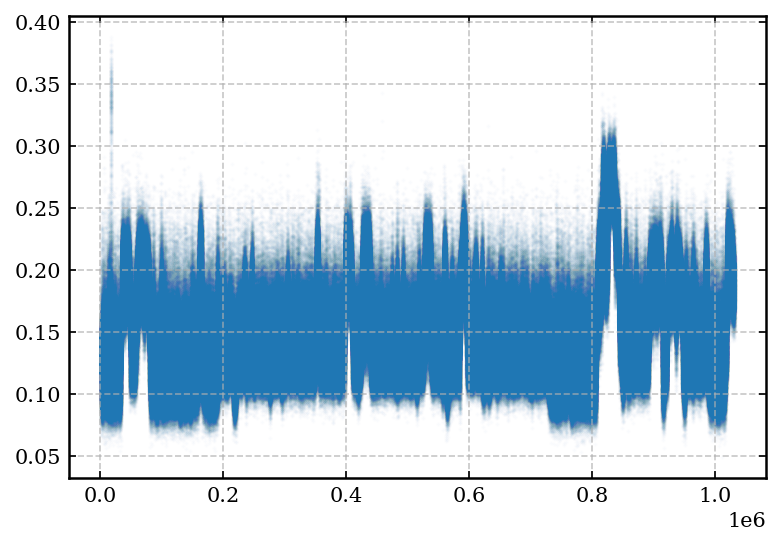

In [ ]:
plt.scatter(time, rmsd, s=1, alpha=0.01)